Lecture 5 — Class Exercise
Distribution Charts: Airbnb London
Push to: week05/lecture05_exercise.ipynb

Rules:

Cap price outliers at 95th percentile — annotate this
Every chart has a median/mean reference line with annotation
Insight title names the distribution shape or key finding
Colour has meaning — don't use colour just for decoration

In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('/content/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [3]:
# Clean the price column: remove non-numeric characters (like symbols and commas) and convert to float
if df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace(r'[^\d.]', '', regex=True)
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))

95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


Task 1 — Histogram: price by room type (overlapping distributions)
What to build: A histogram showing price distributions for Entire home/apt vs Private room (exclude Shared room — too few observations) overlaid on the same chart.

Requirements:

Both room types on the same chart (use color='room_type')
barmode='overlay' with opacity=0.6 so both distributions are visible
A vertical line for the median of EACH room type, differently coloured
Insight title comparing the two distributions

95th percentile price: 372.66
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


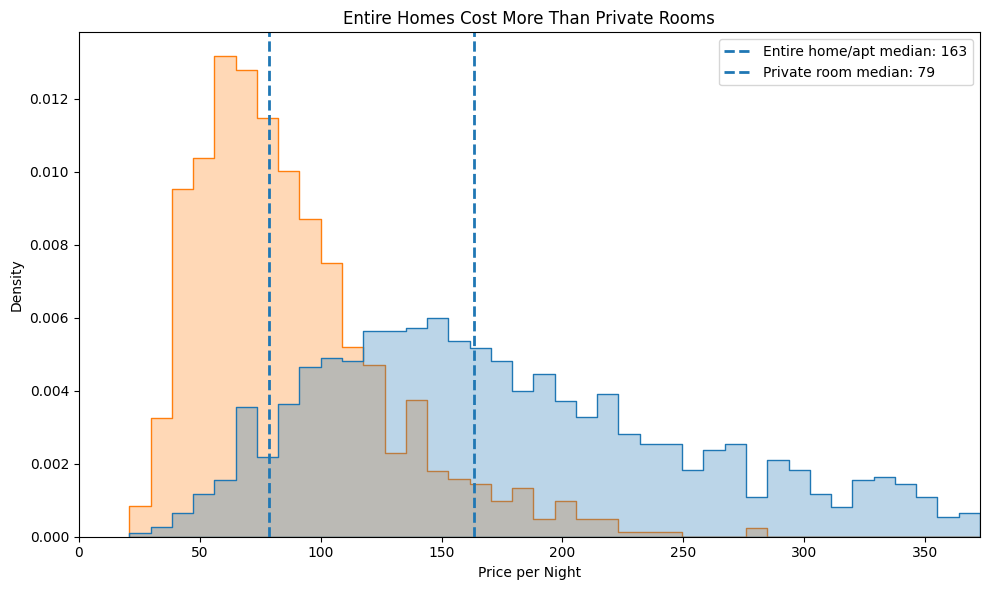

In [4]:
# Task 1
# YOUR CODE HERE
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean the price column and convert it to numbers
df['price'] = (
    df['price']
    .astype(str)
    .str.replace(r'[^0-9.]', '', regex=True)
)

df['price'] = pd.to_numeric(df['price'], errors='coerce')

# 2. Remove missing and invalid prices
df = df[df['price'].notna() & (df['price'] > 0)].copy()

# 3. Calculate the 95th percentile and cap extreme prices
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95].copy()

print(f"95th percentile price: {p95:.2f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))

# 4. Select the two room types
room_types = ['Entire home/apt', 'Private room']
plot_df = df_cap[df_cap['room_type'].isin(room_types)]

# 5. Draw overlapping histograms
plt.figure(figsize=(10, 6))

sns.histplot(
    data=plot_df,
    x='price',
    hue='room_type',
    bins=40,
    element='step',
    stat='density',
    common_norm=False,
    alpha=0.3
)

# 6. Add a median line for each room type
for room in room_types:
    median_price = plot_df.loc[
        plot_df['room_type'] == room, 'price'
    ].median()

    plt.axvline(
        median_price,
        linestyle='--',
        linewidth=2,
        label=f'{room} median: {median_price:.0f}'
    )

plt.title('Entire Homes Cost More Than Private Rooms')
plt.xlabel('Price per Night')
plt.ylabel('Density')
plt.xlim(0, p95)
plt.legend()
plt.tight_layout()
plt.show()

Task 2 — Box plot: listing activity by borough
What to build: A horizontal box plot comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

Requirements:

Horizontal orientation (borough names are long)
Sorted by median reviews per month (most active at top)
Highlight the two most active boroughs in a different colour
Outliers shown as individual points
Insight title naming the two busiest boroughs
💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

In [5]:
# Task 2
# Borough column name differs between Airbnb exports — pick whichever exists
borough_col = next(c for c in ['neighbourhood', 'neighbourhood_cleansed', 'borough'] if c in df.columns)

# Remove new/inactive listings (zero or missing reviews)
act = df[df['reviews_per_month'] > 0].copy()

# Order boroughs by median activity
order = act.groupby(borough_col)['reviews_per_month'].median().sort_values(ascending=False)
top2 = order.index[:2].tolist()

# Colour = highlight (top 2 vs the rest)
act['group'] = np.where(act[borough_col].isin(top2), 'Two most active', 'Other boroughs')

fig2 = px.box(
    act, x='reviews_per_month', y=borough_col, color='group',
    orientation='h', points='outliers',
    # px puts the first category at the top for horizontal charts → most active first
    category_orders={borough_col: order.index.tolist(),
                     'group': ['Two most active', 'Other boroughs']},
    color_discrete_map={'Two most active': '#d62728', 'Other boroughs': '#b0b0b0'},
    labels={'reviews_per_month': 'Reviews per month (booking-activity proxy)', borough_col: ''},
    title=(f"{top2[0]} and {top2[1]} are London's busiest boroughs — "
           f"median {order.iloc[0]:.2f} and {order.iloc[1]:.2f} reviews/month")
)

# London-wide median reference line
overall_med = act['reviews_per_month'].median()
fig2.add_vline(x=overall_med, line_dash='dash', line_color='black',
               annotation_text=f"London median: {overall_med:.2f}",
               annotation_position='top right')

fig2.add_annotation(xref='paper', yref='paper', x=1, y=-0.06, showarrow=False,
                    xanchor='right', font=dict(size=11, color='grey'),
                    text=f"Listings with zero reviews excluded (n = {len(act):,} active listings)")

fig2.update_layout(boxmode='overlay',      # stop the two colour groups being offset
                   height=max(500, 28 * order.size),
                   legend_title='', template='simple_white')
fig2.show()
